In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import colorsys

from sklearn import tree
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance

In [2]:
# Load the dataset
df = pd.read_csv('data/student_habits_performance.csv')
display(df.head())

,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [3]:
# Create a binary classification target from exam_score (1 = Pass >= 70, 0 = Fail < 70)
df['passed'] = df['exam_score'].apply(lambda x: 1 if x >= 70.0 else 0)

# Encode binary categorical features (0 or 1)
df['part_time_job_num'] = df['part_time_job'].map({'No': 0, 'Yes': 1})
df['extracurricular_num'] = df['extracurricular_participation'].map({'No': 0, 'Yes': 1})

# Encode ordered categorical features (1, 2, 3)
df['diet_quality_num'] = df['diet_quality'].map({'Poor': 1, 'Fair': 2, 'Good': 3})
df['internet_quality_num'] = df['internet_quality'].map({'Poor': 1, 'Average': 2, 'Good': 3})

# Define feature columns and target
feature_cols = [
    'study_hours_per_day', 
    'social_media_hours', 
    'netflix_hours', 
    'attendance_percentage', 
    'sleep_hours', 
    'exercise_frequency', 
    'mental_health_rating',
    'part_time_job_num',
    'diet_quality_num'
]

X = df[feature_cols]
y = df['passed']

display(X.head())

,study_hours_per_day,social_media_hours,netflix_hours,attendance_percentage,sleep_hours,exercise_frequency,mental_health_rating,part_time_job_num,diet_quality_num
0,0.0,1.2,1.1,85.0,8.0,6,8,0,2
1,6.9,2.8,2.3,97.3,4.6,6,8,0,3
2,1.4,3.1,1.3,94.8,8.0,1,1,0,1
3,1.0,3.9,1.0,71.0,9.2,4,1,0,1
4,5.0,4.4,0.5,90.9,4.9,3,1,0,2


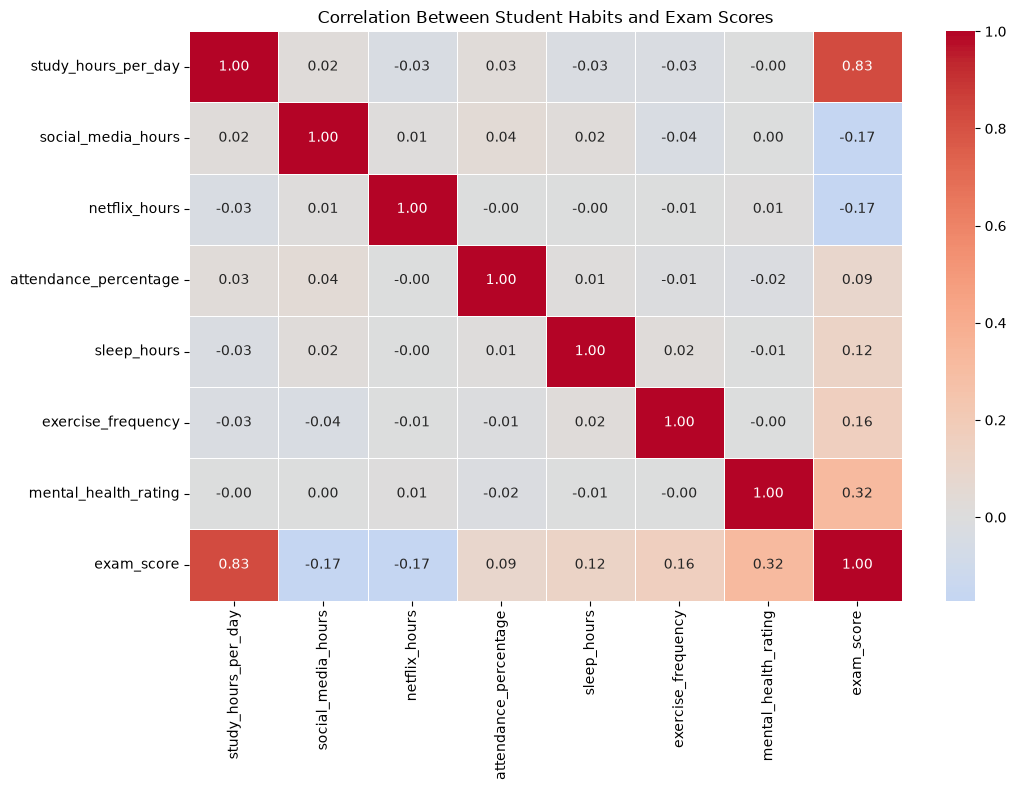

In [4]:
# Select numerical variables
corr_cols = [
    'study_hours_per_day',
    'social_media_hours',
    'netflix_hours',
    'attendance_percentage',
    'sleep_hours',
    'exercise_frequency',
    'mental_health_rating',
    'exam_score'
]

correlation_matrix = df[corr_cols].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Between Student Habits and Exam Scores")
plt.tight_layout()
plt.show()

In [5]:
# Train-test split for all future use
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y
)

# Standardize the features (fit only on training data)
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (750, 9)
Testing set size: (250, 9)


Shallow Tree (max_depth=2)
Training accuracy: 0.808
Testing accuracy: 0.768


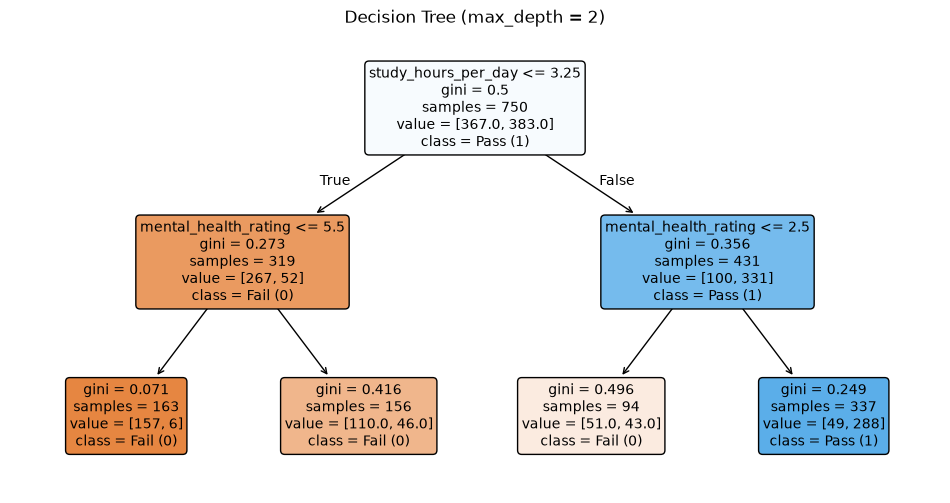

In [6]:
# Fit a shallow classification tree with max_depth=2
treeclf_shallow = DecisionTreeClassifier(max_depth=2, random_state=1)
treeclf_shallow.fit(X_train, y_train)

# Evaluate performance on training and testing data
shallow_train_accuracy = accuracy_score(
    y_train,
    treeclf_shallow.predict(X_train)
)

shallow_test_accuracy = accuracy_score(
    y_test,
    treeclf_shallow.predict(X_test)
)

print("Shallow Tree (max_depth=2)")
print("Training accuracy:", round(shallow_train_accuracy, 3))
print("Testing accuracy:", round(shallow_test_accuracy, 3))

# Visualize the tree
plt.figure(figsize=(12, 6))
plot_tree(
    treeclf_shallow, 
    feature_names=feature_cols, 
    class_names=['Fail (0)', 'Pass (1)'], 
    filled=True, 
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree (max_depth = 2)")
plt.show()

Deep Tree (max_depth=4)
Training Accuracy: 0.875
Testing Accuracy: 0.76


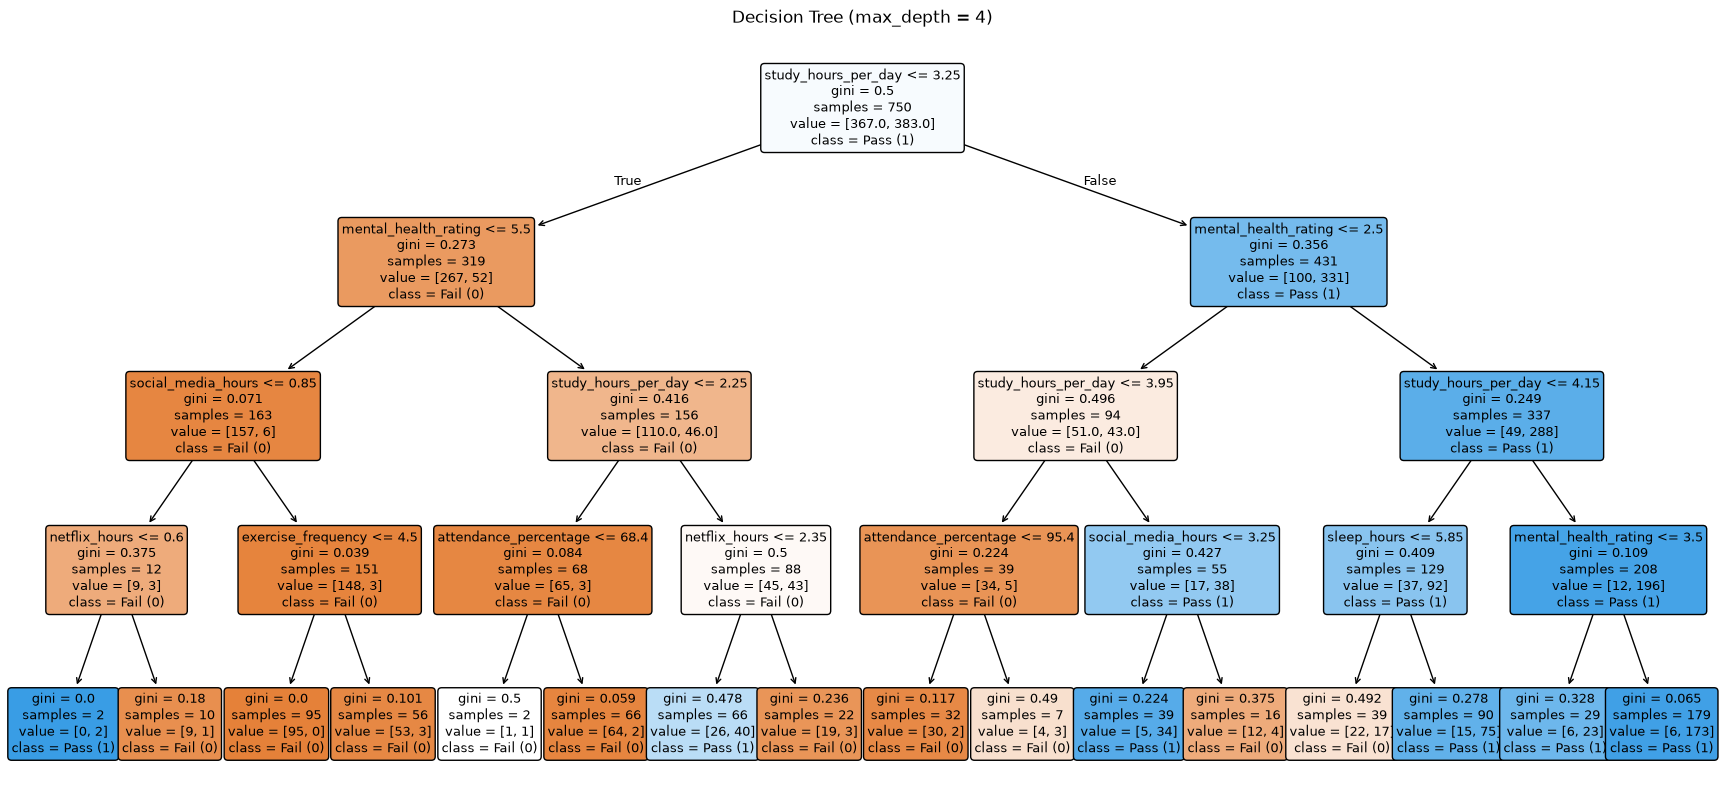

,feature,importance_depth_2,importance_depth_4
0,study_hours_per_day,0.798779,0.721575
6,mental_health_rating,0.201221,0.147970
2,netflix_hours,0.000000,0.041831
1,social_media_hours,0.000000,0.041706
4,sleep_hours,0.000000,0.036028
3,attendance_percentage,0.000000,0.010042
5,exercise_frequency,0.000000,0.000848
7,part_time_job_num,0.000000,0.000000
8,diet_quality_num,0.000000,0.000000


In [7]:
# Fit a deeper classification tree with max_depth=4
treeclf_deep = DecisionTreeClassifier(
    max_depth=4,
    random_state=1
)
treeclf_deep.fit(X_train, y_train)

# Evaluate performance on training and testing data
deep_train_accuracy = accuracy_score(
    y_train,
    treeclf_deep.predict(X_train)
)
deep_test_accuracy = accuracy_score(
    y_test,
    treeclf_deep.predict(X_test)
)

print("Deep Tree (max_depth=4)")
print("Training Accuracy:", round(deep_train_accuracy, 3))
print("Testing Accuracy:", round(deep_test_accuracy, 3))

# Visualize the deeper tree
plt.figure(figsize=(22, 10))
plot_tree(
    treeclf_deep,
    feature_names=feature_cols,
    class_names=['Fail (0)', 'Pass (1)'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree (max_depth = 4)")
plt.show()

# Compare Gini feature importances (professor's method)
importance_df = pd.DataFrame({
    'feature': feature_cols,
    'importance_depth_2': treeclf_shallow.feature_importances_,
    'importance_depth_4': treeclf_deep.feature_importances_
}).sort_values(by='importance_depth_4', ascending=False)

display(importance_df)

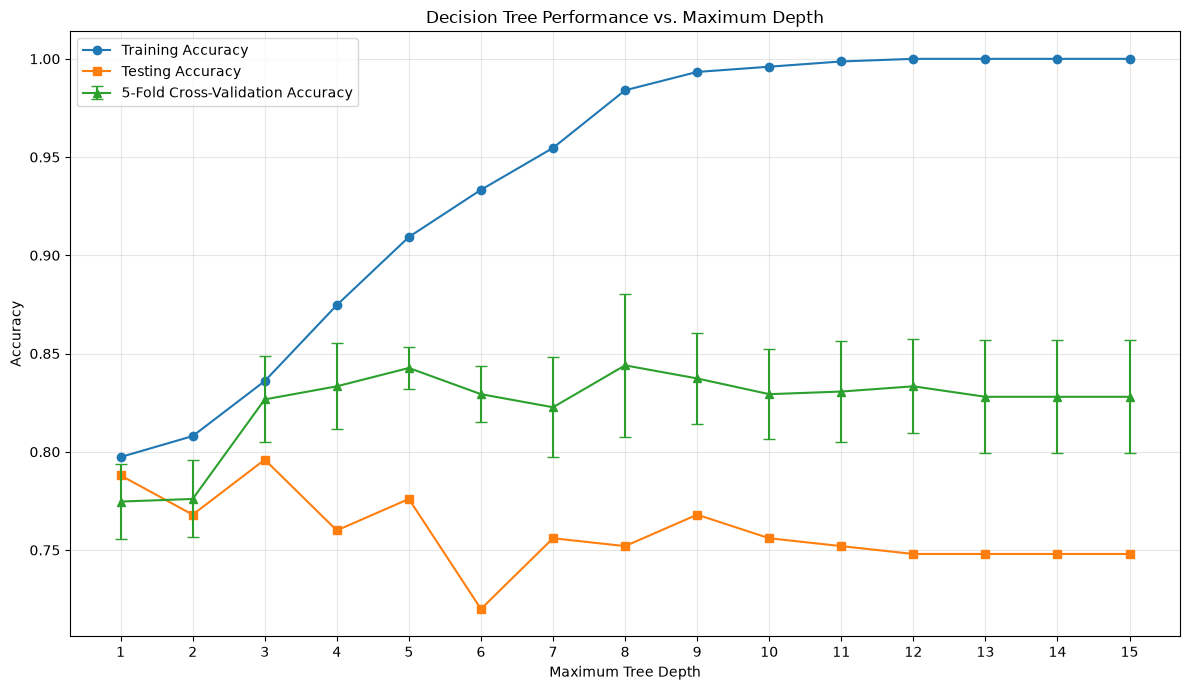

,Maximum Depth,Training Accuracy,Testing Accuracy,Mean CV Accuracy,CV Standard Deviation
0,1,0.797,0.788,0.775,0.019
1,2,0.808,0.768,0.776,0.020
2,3,0.836,0.796,0.827,0.022
3,4,0.875,0.760,0.833,0.022
4,5,0.909,0.776,0.843,0.011
5,6,0.933,0.720,0.829,0.014
6,7,0.955,0.756,0.823,0.026
7,8,0.984,0.752,0.844,0.036
8,9,0.993,0.768,0.837,0.023
9,10,0.996,0.756,0.829,0.023


Best tree depth based on cross-validation: 8
Mean cross-validation accuracy: 0.844


In [8]:
# Decision Tree Depth Experiment:
# Comparing training, testing, and cross-validation accuracy

depths = range(1, 16)
train_accuracies = []
test_accuracies = []
cv_accuracies = []
cv_std = []

# Evaluate decision trees with maximum depths from 1 to 15
for depth in depths:
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=1
    )
    # Train the model
    model.fit(X_train, y_train)
    # Calculate training accuracy
    train_pred = model.predict(X_train)
    train_accuracies.append(
        accuracy_score(y_train, train_pred)
    )
    # Calculate testing accuracy
    test_pred = model.predict(X_test)
    test_accuracies.append(
        accuracy_score(y_test, test_pred)
    )
    # Perform 5-fold cross-validation on training data
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring='accuracy'
    )
    cv_accuracies.append(scores.mean())
    cv_std.append(scores.std())

# Plot the results
plt.figure(figsize=(12, 7))
plt.plot(
    depths,
    train_accuracies,
    marker='o',
    label='Training Accuracy'
)
plt.plot(
    depths,
    test_accuracies,
    marker='s',
    label='Testing Accuracy'
)
plt.errorbar(
    depths,
    cv_accuracies,
    yerr=cv_std,
    marker='^',
    capsize=4,
    label='5-Fold Cross-Validation Accuracy'
)
plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree Performance vs. Maximum Depth")
plt.xticks(list(depths))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display numerical results
depth_results = pd.DataFrame({
    'Maximum Depth': list(depths),
    'Training Accuracy': train_accuracies,
    'Testing Accuracy': test_accuracies,
    'Mean CV Accuracy': cv_accuracies,
    'CV Standard Deviation': cv_std
})

display(depth_results.round(3))

# Identify the depth with the highest cross-validation accuracy
best_depth = list(depths)[
    np.argmax(cv_accuracies)
]
print(
    f"Best tree depth based on cross-validation: {best_depth}"
)
print(
    f"Mean cross-validation accuracy: "
    f"{max(cv_accuracies):.3f}"
)

In [9]:
# Dr. Edwards' function to draw the neural network (red = negative weight, blue = positive)
def show_ann(mlp):
    hidden_layers_n = len(mlp.coefs_) - 1
    layers_n = hidden_layers_n + 2
    input_neurons_n = len(mlp.coefs_[0])
    hidden_neurons_n = [len(mlp.coefs_[i+1]) for i in range(hidden_layers_n)]
    output_neurons_n = len(mlp.coefs_[-1][0])

    G = nx.DiGraph()
    pos = {}

    # Create the neurons of the input layer
    for i in range(input_neurons_n):
        pos['Layer0_{}'.format(i)] = (i, layers_n - 1)

    for j in range(hidden_layers_n):
        # Create the neurons of the j'th hidden layer
        prev_layer = j
        cur_layer = j + 1
        if (j == 0):
            prev_size = input_neurons_n
        else:
            prev_size = hidden_neurons_n[j - 1]
        for i in range(hidden_neurons_n[j]):
            pos['Layer{}_{}'.format(cur_layer, i)] = (i, layers_n - 1 - cur_layer)
            for k in range(prev_size):
                w = mlp.coefs_[prev_layer][k][i]
                G.add_edge('Layer{}_{}'.format(prev_layer, k), 'Layer{}_{}'.format(cur_layer, i), weight=w)

    # Create the neurons of the output layer
    prev_layer = hidden_layers_n
    cur_layer = hidden_layers_n + 1
    for i in range(output_neurons_n):
        pos['Layer{}_{}'.format(cur_layer, i)] = (i, layers_n - 1 - cur_layer)
        for k in range(hidden_neurons_n[-1]):
            w = mlp.coefs_[prev_layer][k][i]
            G.add_edge('Layer{}_{}'.format(prev_layer, k), 'Layer{}_{}'.format(cur_layer, i), weight=w)

    edges = G.edges()
    colors = [colorsys.hsv_to_rgb(0 if G[u][v]['weight'] < 0 else 0.65, 1, 1) for u, v in edges]
    weights = [abs(G[u][v]['weight']) * 2 for u, v in edges]

    nx.draw(G, pos, node_color='y', node_size=450, width=weights, edge_color=colors)

--- Architecture 1: (5,) ---
[[105  17]
 [  8 120]]
              precision    recall  f1-score   support

           0       0.93      0.86      0.89       122
           1       0.88      0.94      0.91       128

    accuracy                           0.90       250
   macro avg       0.90      0.90      0.90       250
weighted avg       0.90      0.90      0.90       250



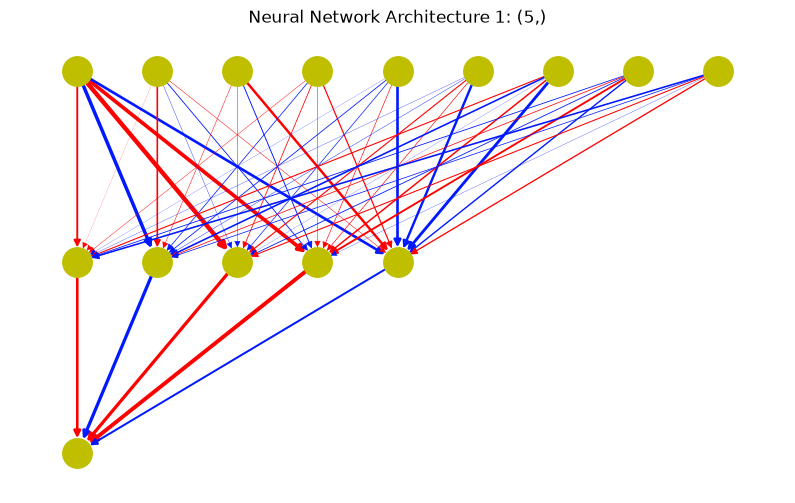

In [10]:
# Architecture 1: 1 hidden layer with 5 nodes
mlp1 = MLPClassifier(hidden_layer_sizes=(5,), max_iter=5000, random_state=1)
mlp1.fit(X_train_scaled, y_train)

predictions1 = mlp1.predict(X_test_scaled)
print("--- Architecture 1: (5,) ---")
print(confusion_matrix(y_test, predictions1))
print(classification_report(y_test, predictions1))

plt.figure(figsize=(10, 6))
plt.title("Neural Network Architecture 1: (5,)")
show_ann(mlp1)
plt.show()

--- Architecture 2: (9, 5) ---
[[105  17]
 [ 13 115]]
              precision    recall  f1-score   support

           0       0.89      0.86      0.88       122
           1       0.87      0.90      0.88       128

    accuracy                           0.88       250
   macro avg       0.88      0.88      0.88       250
weighted avg       0.88      0.88      0.88       250



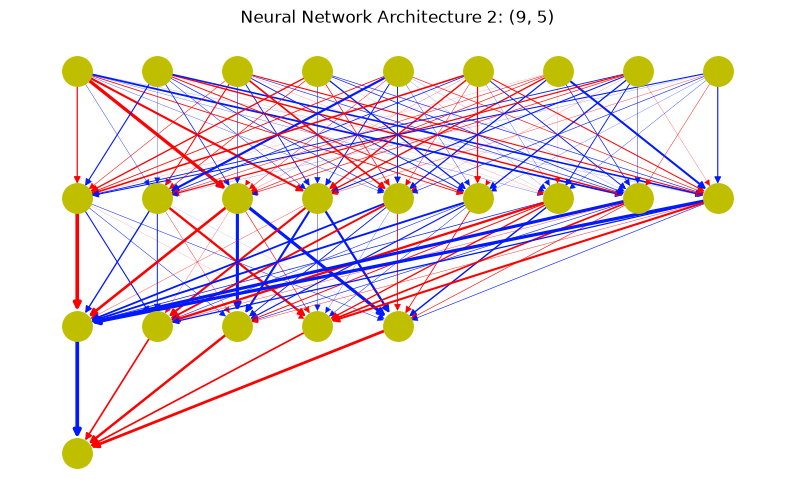

In [11]:
# Architecture 2: 2 hidden layers with 9 and 5 nodes
mlp2 = MLPClassifier(hidden_layer_sizes=(9, 5), max_iter=5000, random_state=1)
mlp2.fit(X_train_scaled, y_train)

predictions2 = mlp2.predict(X_test_scaled)
print("--- Architecture 2: (9, 5) ---")
print(confusion_matrix(y_test, predictions2))
print(classification_report(y_test, predictions2))

plt.figure(figsize=(10, 6))
plt.title("Neural Network Architecture 2: (9, 5)")
show_ann(mlp2)
plt.show()

--- Architecture 3: (12, 8, 4) ---
[[107  15]
 [ 19 109]]
              precision    recall  f1-score   support

           0       0.85      0.88      0.86       122
           1       0.88      0.85      0.87       128

    accuracy                           0.86       250
   macro avg       0.86      0.86      0.86       250
weighted avg       0.86      0.86      0.86       250



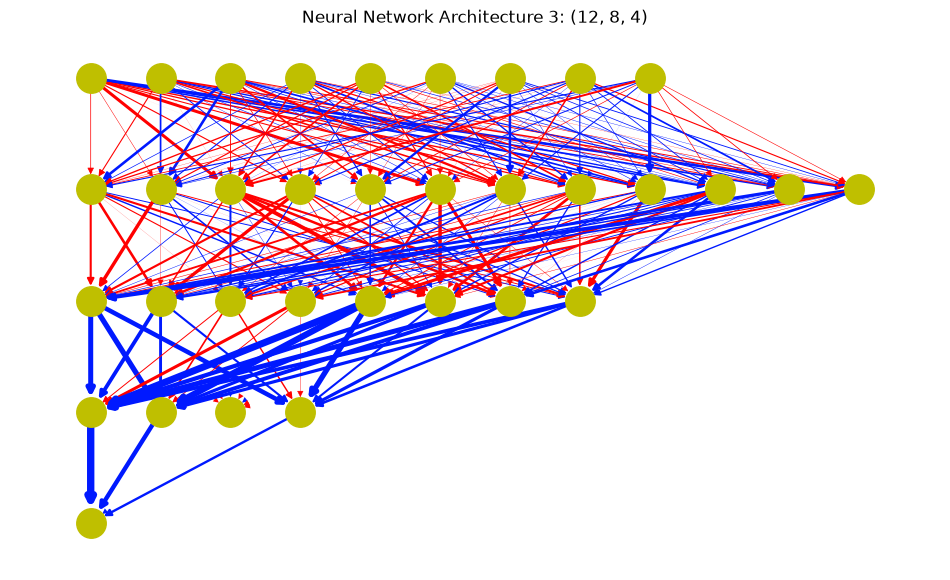

In [12]:
# Architecture 3: 3 hidden layers with 12, 8, and 4 nodes
mlp3 = MLPClassifier(hidden_layer_sizes=(12, 8, 4), max_iter=5000, random_state=1)
mlp3.fit(X_train_scaled, y_train)

predictions3 = mlp3.predict(X_test_scaled)
print("--- Architecture 3: (12, 8, 4) ---")
print(confusion_matrix(y_test, predictions3))
print(classification_report(y_test, predictions3))

plt.figure(figsize=(12, 7))
plt.title("Neural Network Architecture 3: (12, 8, 4)")
show_ann(mlp3)
plt.show()

In [13]:
# Consolidated Results for easier screenshotting
models = {
    'Neural Network (5,)': mlp1,
    'Neural Network (9,5)': mlp2,
    'Neural Network (12,8,4)': mlp3
}
results = []

for name, model in models.items():
    predictions = model.predict(X_test_scaled)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': classification_report(
            y_test,
            predictions,
            output_dict=True
        )['1']['precision'],
        'Recall': classification_report(
            y_test,
            predictions,
            output_dict=True
        )['1']['recall'],
        'F1 Score': classification_report(
            y_test,
            predictions,
            output_dict=True
        )['1']['f1-score']
    })

results_df = pd.DataFrame(results)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,"Neural Network (5,)",0.900,0.876,0.938,0.906
1,"Neural Network (9,5)",0.880,0.871,0.898,0.885
2,"Neural Network (12,8,4)",0.864,0.879,0.852,0.865


In [14]:
# Calculate the average absolute edge weight leaving each input node (Layer 0 -> Layer 1)
comparison_df = pd.DataFrame({
    'input_node': [f'Layer0_{i}' for i in range(len(feature_cols))],
    'feature': feature_cols,
    'tree_depth_2_gini': treeclf_shallow.feature_importances_,
    'tree_depth_4_gini': treeclf_deep.feature_importances_,
    'nn1_mean_abs_weight': np.mean(np.abs(mlp1.coefs_[0]), axis=1),
    'nn2_mean_abs_weight': np.mean(np.abs(mlp2.coefs_[0]), axis=1),
    'nn3_mean_abs_weight': np.mean(np.abs(mlp3.coefs_[0]), axis=1)
}).sort_values(by='tree_depth_4_gini', ascending=False)

display(comparison_df)

,input_node,feature,tree_depth_2_gini,tree_depth_4_gini,nn1_mean_abs_weight,nn2_mean_abs_weight,nn3_mean_abs_weight
0,Layer0_0,study_hours_per_day,0.798779,0.721575,1.159331,0.411102,0.539384
6,Layer0_6,mental_health_rating,0.201221,0.147970,0.521403,0.267461,0.327106
2,Layer0_2,netflix_hours,0.000000,0.041831,0.310197,0.295422,0.470733
1,Layer0_1,social_media_hours,0.000000,0.041706,0.251319,0.294583,0.372741
4,Layer0_4,sleep_hours,0.000000,0.036028,0.356836,0.265481,0.313561
3,Layer0_3,attendance_percentage,0.000000,0.010042,0.263153,0.239908,0.364937
5,Layer0_5,exercise_frequency,0.000000,0.000848,0.349915,0.314913,0.261365
7,Layer0_7,part_time_job_num,0.000000,0.000000,0.405635,0.271585,0.338415
8,Layer0_8,diet_quality_num,0.000000,0.000000,0.357347,0.170309,0.349352


In [15]:
# Permutation Importance
# Calculate a model's original accuracy, shuffle one feature in the testing
# dataset, calculate again, and check the decrease in performance

# Calculate permutation importance for shallow decision tree
tree_perm = permutation_importance(
    treeclf_shallow,
    X_test,
    y_test,
    n_repeats=20,
    random_state=1,
    scoring='accuracy'
)

# Calculate permutation importance for first neural network model
nn_perm = permutation_importance(
    mlp1,
    X_test_scaled,
    y_test,
    n_repeats=20,
    random_state=1,
    scoring='accuracy'
)

# Create comparison dataframe
perm_df = pd.DataFrame({
    'Feature': feature_cols,
    'Decision Tree Importance': tree_perm.importances_mean,
    'Neural Network Importance': nn_perm.importances_mean
})
perm_df = perm_df.sort_values(
    'Decision Tree Importance',
    ascending=False
)
display(perm_df)

,Feature,Decision Tree Importance,Neural Network Importance
0,study_hours_per_day,0.2406,0.3048
6,mental_health_rating,0.0392,0.1176
1,social_media_hours,0.0000,0.0516
3,attendance_percentage,0.0000,0.0192
2,netflix_hours,0.0000,0.0280
4,sleep_hours,0.0000,0.0434
5,exercise_frequency,0.0000,0.0424
7,part_time_job_num,0.0000,0.0004
8,diet_quality_num,0.0000,0.0090


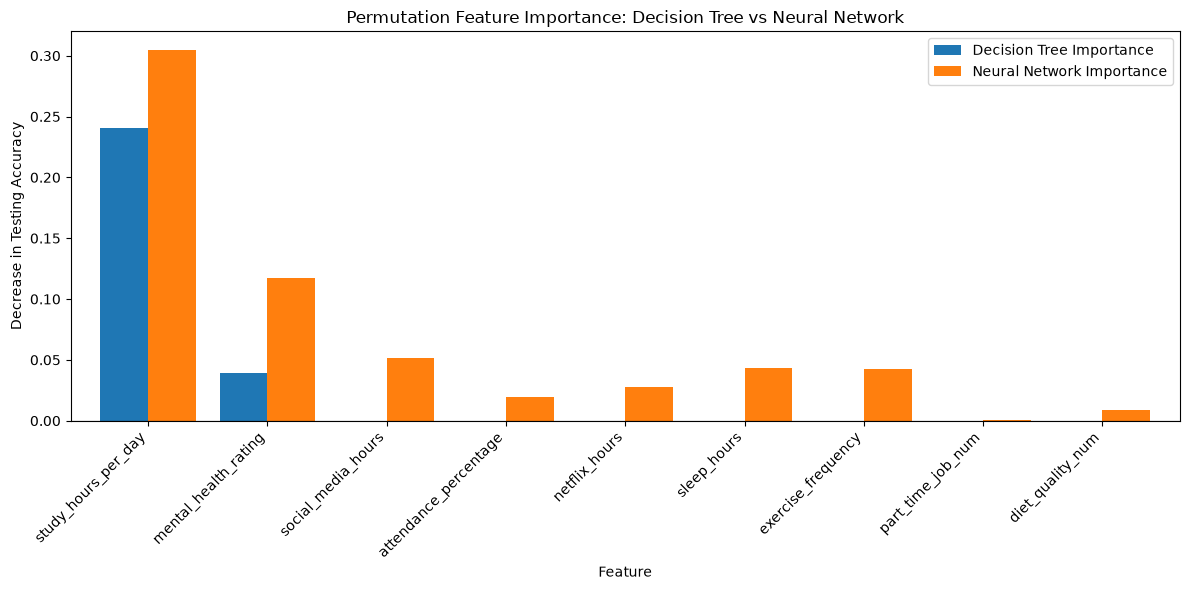

In [16]:
perm_plot = perm_df.set_index('Feature')

perm_plot.plot(
    kind='bar',
    figsize=(12, 6),
    width=0.8
)

plt.title("Permutation Feature Importance: Decision Tree vs Neural Network")
plt.ylabel("Decrease in Testing Accuracy")
plt.xlabel("Feature")
plt.xticks(rotation=45, ha='right')
plt.axhline(0, color='black', linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()